# Inspect SAMap label-transfer results

Loads a fitted `samap.pkl` and reproduces the cross-species dec/fib transfer **exactly** as the
`samap_label_stain` rule does (by importing the same tested functions), so what you see here is
what the figures are built from.

**Kernel:** must be the samap env
(`.../xmens_final/envs/samap/.venv`). If `import samap` fails with a `GLIBCXX`/`CXXABI` error, the
kernel didn't get `gcc/14`'s `libstdc++` on its path — register the kernel with
`LD_LIBRARY_PATH` pointing at gcc-14's lib64, or start Jupyter after `module load gcc/14.2.0-fasrc01`.

Pick which run to inspect in the config cell.

In [1]:
# --- config -------------------------------------------------------------------------------
SCRIPTS = "/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/workflow/scripts"
RUNS    = "/n/lab_storage/eddy_lab/users/nhilgert/decidualization/revisions/samap_integrate/runs"

RUN = "menstrual_x_4dpi_hmmer"          # or "secretory_x_1dpi_late_hmmer"

import sys
if SCRIPTS not in sys.path:
    sys.path.insert(0, SCRIPTS)

import numpy as np
import pandas as pd
import transfer_label_staining as T     # the SAME module the rule runs — reuse its tested funcs

In [2]:
# --- env sanity: compiled deps load? (GLIBCXX/CXXABI check) -------------------------------
import hnswlib, samap, scanpy, anndata
print("ok  anndata", anndata.__version__, "| scanpy", scanpy.__version__)

ok  anndata 0.12.19 | scanpy 1.11.5


/tmp/ipykernel_1196140/3304046080.py:3: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print("ok  anndata", anndata.__version__, "| scanpy", scanpy.__version__)
/tmp/ipykernel_1196140/3304046080.py:3: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("ok  anndata", anndata.__version__, "| scanpy", scanpy.__version__)


In [3]:
# --- load the fitted joint object (~7 GB pkl; a couple of minutes, held for the session) --
import os
pkl = os.path.join(RUNS, RUN, "samap.pkl")
print("loading", pkl)
joint = T.get_combined_adata(T.load_samap(pkl))
is_h, is_m = T.species_masks(joint)
print(f"joint: {joint.n_obs} cells  |  human {int(is_h.sum())}  mouse {int(is_m.sum())}")
print("obs columns:", list(joint.obs.columns))

loading /n/lab_storage/eddy_lab/users/nhilgert/decidualization/revisions/samap_integrate/runs/menstrual_x_4dpi_hmmer/samap.pkl
joint: 30233 cells  |  human 24092  mouse 6141
obs columns: ['hs_sample', 'hs_cell_barcode', 'hs_timepoint', 'hs_coarse_refined', 'hs_fine_refined', 'hs_origin_lineage', 'hs_lineage', 'hs_cell_type', 'hs_subtype', 'hs_annotation_level', 'hs_cell_type_annotations', 'hs_cell_subtype_annotations', 'hs_leiden_clusters', 'mm_sample', 'mm_cell_barcode', 'mm_timepoint', 'mm_coarse_refined', 'mm_fine_refined', 'mm_origin_lineage', 'mm_cell_type_annotations', 'mm_cell_subtype_annotations', 'mm_leiden_clusters', 'batch', 'species']


## 1. Settle the `unassigned` question

The prep only writes `decidual cells` / `endometrial fibroblasts`. `unassigned` in the stats JSON
should be SAMap's cross-species *fill* — i.e. the human column carries real labels on human cells
and `unassigned` on mouse cells (and vice versa). If that's what we see, there's no accounting bug:
the transfer uses each cell's OWN-species column, so the fill never enters the dec/fib call.

In [4]:
HS, MM = T.HS_ANNOT_COL, T.MM_ANNOT_COL     # 'hs_cell_type_annotations', 'mm_cell_type_annotations'

def vc(series, mask):
    return dict(pd.Series(series[mask]).value_counts())

print("hs_annot on HUMAN cells :", vc(joint.obs[HS], is_h))   # expect: only decidual/fibroblast
print("hs_annot on MOUSE cells :", vc(joint.obs[HS], is_m))   # expect: only 'unassigned' (the fill)
print()
print("mm_annot on MOUSE cells :", vc(joint.obs[MM], is_m))   # expect: only decidual/fibroblast
print("mm_annot on HUMAN cells :", vc(joint.obs[MM], is_h))   # expect: only 'unassigned' (the fill)

hs_annot on HUMAN cells : {'decidual cells': 16098, 'endometrial fibroblasts': 7994}
hs_annot on MOUSE cells : {'unassigned': 6141}

mm_annot on MOUSE cells : {'decidual cells': 4859, 'endometrial fibroblasts': 1282}
mm_annot on HUMAN cells : {'unassigned': 24092}


## 2. Reproduce the transfer (identical to the rule)

`binary_labels` -> own-species dec(1)/fib(0)/none(-1); `project` -> connectivity-weighted decidual
fraction among cross-species neighbors; threshold 0.5. This is the rule's computation, verbatim.

In [5]:
C = joint.obsp[T.GRAPH_KEY].tocsr()
y = T.binary_labels(joint.obs, is_h)                         # independent (own-species) label

dec = np.where(y == 1, 1.0, np.where(y == 0, 0.0, np.nan))
frac_h, nz_h = T.project(C, is_m, dec)                       # human <- mouse neighbors
frac_m, nz_m = T.project(C, is_h, dec)                       # mouse <- human neighbors

transf = np.full(joint.n_obs, -1)
transf[is_h & nz_h] = (frac_h[is_h & nz_h] >= 0.5).astype(int)
transf[is_m & nz_m] = (frac_m[is_m & nz_m] >= 0.5).astype(int)

LAB = {1: "decidual", 0: "fibroblast", -1: "none"}
print("independent:", {LAB[k]: int((y == k).sum()) for k in (1, 0, -1)})
print("transferred:", {LAB[k]: int((transf == k).sum()) for k in (1, 0, -1)})

independent: {'decidual': 20957, 'fibroblast': 9276, 'none': 0}
transferred: {'decidual': 22688, 'fibroblast': 7529, 'none': 16}


## 3. The actual result — confusion matrices (independent vs transferred), per species

Diagonal = agreement. The off-diagonal **fibroblast -> decidual** cell is the biologically
interesting bleed (the decidualization transition), and it's what the `fib_recall` numbers in the
stats JSON summarize. The `none` column = cells with no cross-species neighbor (should be tiny).

In [6]:
def confusion(mask, name):
    ix = np.where(mask)[0]
    ct = pd.crosstab(pd.Series([LAB[v] for v in y[ix]],      name="independent"),
                     pd.Series([LAB[v] for v in transf[ix]], name="transferred"))
    print(f"=== {name}  (n={len(ix)}) ===")
    print(ct)
    # recall on the diagonal, matching the stats JSON
    for lab, code_ in (("decidual", 1), ("fibroblast", 0)):
        d = (y[ix] == code_)
        if d.sum():
            rec = float(np.mean(transf[ix][d] == code_))
            print(f"  {lab:11s} recall = {rec:.3f}  (n={int(d.sum())})")
    print()

confusion(is_h, "HUMAN  (independent human labels vs labels voted from mouse)")
confusion(is_m, "MOUSE  (independent mouse labels vs labels voted from human)")

=== HUMAN  (independent human labels vs labels voted from mouse)  (n=24092) ===
transferred  decidual  fibroblast  none
independent                            
decidual        13561        2534     3
fibroblast       4297        3684    13
  decidual    recall = 0.842  (n=16098)
  fibroblast  recall = 0.461  (n=7994)

=== MOUSE  (independent mouse labels vs labels voted from human)  (n=6141) ===
transferred  decidual  fibroblast
independent                      
decidual         4486         373
fibroblast        344         938
  decidual    recall = 0.923  (n=4859)
  fibroblast  recall = 0.732  (n=1282)



## 4. Did the nine mouse fine subtypes ride through?

Matters if you go on to wire the *fine* (dec1/2/3/decAp, eFib1/2/2i/3/P) transfer rather than just
coarse dec/fib. Should show the subtypes on mouse cells; `unassigned`/empty on human.

In [7]:
for c in ("mm_cell_subtype_annotations", "hs_cell_subtype_annotations"):
    if c in joint.obs.columns:
        m = is_m if c.startswith("mm") else is_h
        print(c, "on own-species cells:")
        print(pd.Series(joint.obs[c][m]).value_counts().head(15).to_string())
        print()
    else:
        print(c, "-> NOT in joint obs")

mm_cell_subtype_annotations on own-species cells:
mm_cell_subtype_annotations
dec2      2916
eFib2i    1086
dec3      1038
decAp      699
dec1       206
eFib1      133
eFib2       24
eFib3       21
eFibP       18

hs_cell_subtype_annotations on own-species cells:
hs_cell_subtype_annotations
    24092



## 5. Spatial check (optional) — do the transferred panels track the independent ones?

Re-runs the stain's own coordinate join + a 2x2 of independent-vs-transferred decidual, per species.
A *good* transfer: the "transferred decidual" territory overlaps the "independent decidual"
territory. Spatially random transferred panels vs structured independent ones = a real problem.
Edit the two npz paths if your coords_root differs.

coord join  human 0.56  mouse 0.72


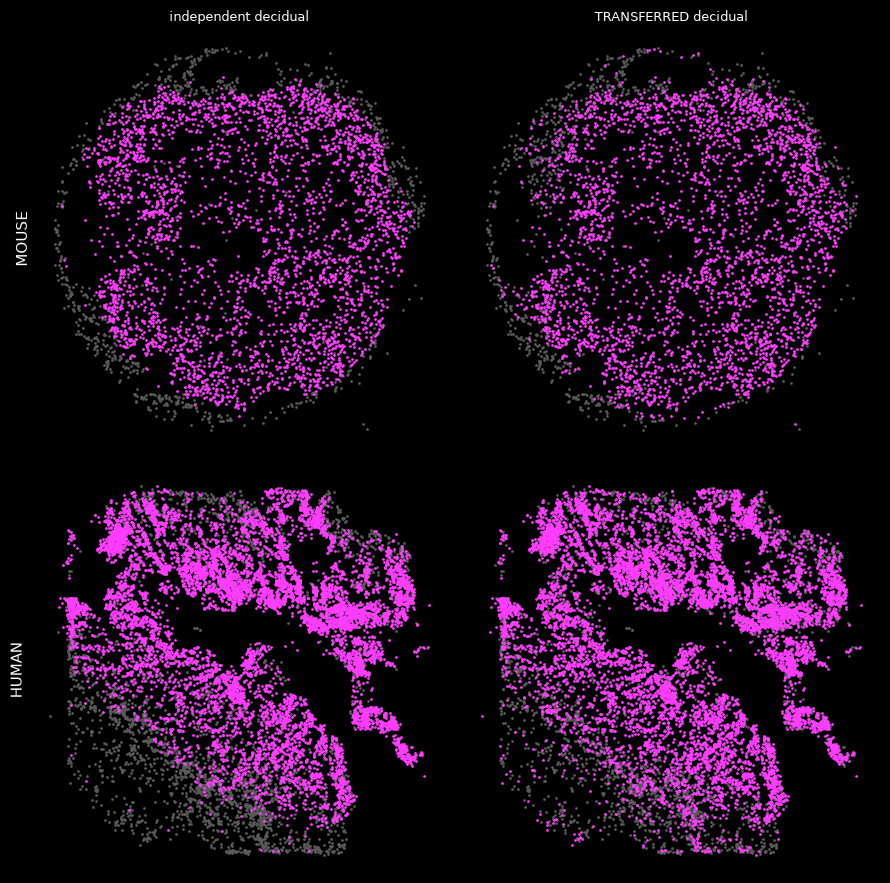

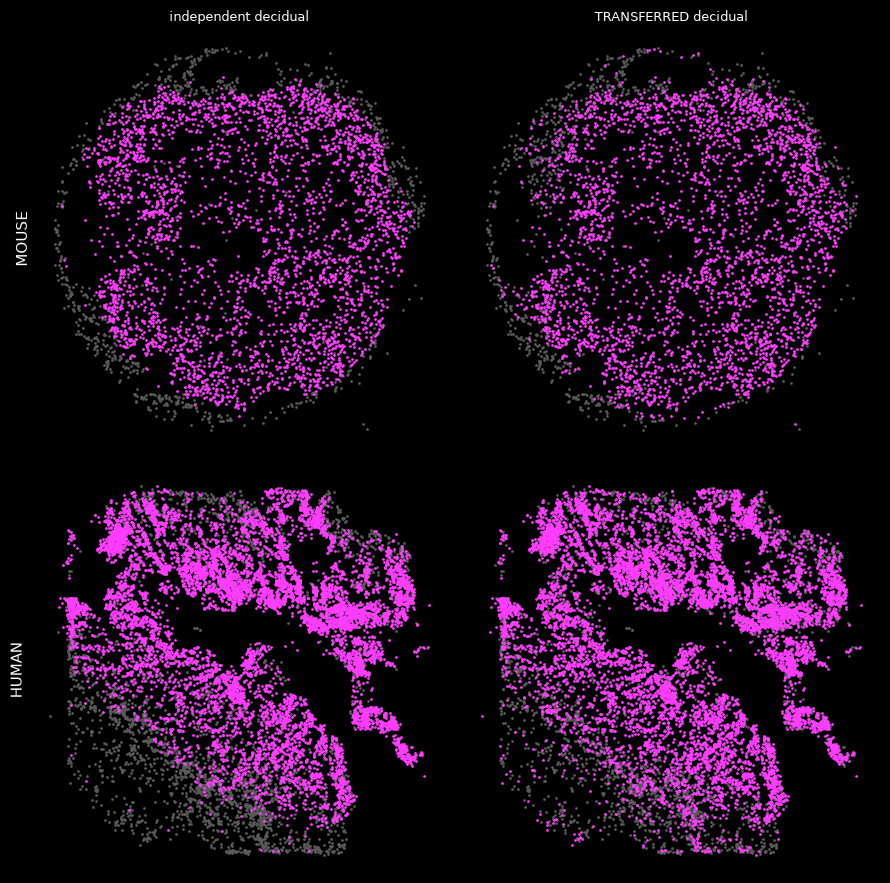

In [12]:
import matplotlib.pyplot as plt

COORDS = "/n/lab_storage/eddy_lab/users/nhilgert/decidualization/revisions/crossspecies_radial_gp"
phase  = RUN.split("_x_")[0]                      # menstrual | secretory
stage  = RUN[len(phase)+3:].rsplit("_hmmer", 1)[0]  # e.g. 4dpi / 1dpi_late
hs_npz = f"{COORDS}/isodepth_{phase}.npz"
mm_npz = f"{COORDS}/transfer_all/radius_{stage}.npz"

Xh, Yh, rh = T.join_coords(joint, T.HS_BC_COL, is_h, hs_npz)
Xm, Ym, rm = T.join_coords(joint, T.MM_BC_COL, is_m, mm_npz)
X = np.where(is_h, Xh, Xm); Y = np.where(is_h, Yh, Ym)
print(f"coord join  human {rh:.2f}  mouse {rm:.2f}")

PINK, GREY = "#FF3DFF", "#5a5a5a"
def panel(ax, smask, lmask, title):
    ax.set_facecolor("black")
    m = smask & np.isfinite(X) & np.isfinite(Y)
    ax.scatter(X[m & ~lmask], Y[m & ~lmask], s=4, c=GREY, linewidths=0)
    ax.scatter(X[m &  lmask], Y[m &  lmask], s=4, c=PINK, linewidths=0)
    ax.set_title(title, color="white", fontsize=9); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])

fig, ax = plt.subplots(2, 2, figsize=(9, 9)); fig.patch.set_facecolor("black")
cols = [("independent decidual", y == 1), ("TRANSFERRED decidual", transf == 1)]
for r, (sm, nm) in enumerate(((is_m, "MOUSE"), (is_h, "HUMAN"))):
    for c, (ttl, lm) in enumerate(cols):
        panel(ax[r, c], sm, lm, ttl if r == 0 else "")
    ax[r, 0].set_ylabel(nm, color="white", fontsize=11)
plt.tight_layout(); plt.show()

In [10]:
plt.show()

In [11]:
import matplotlib
print("backend was:", matplotlib.get_backend())   # if this says 'agg', that's the whole problem
%matplotlib inline
import matplotlib.pyplot as plt

backend was: Agg
